# 01 - Data cleaning

**Goal:** turn the raw UCI Online Retail II export into an analysis-ready transactions table, documenting every decision and how many rows it affects.

**Input:** `data/raw/online_retail_II.xlsx` (two sheets, 2009-12 to 2011-12)
**Output:** `data/processed/transactions_clean.csv`

Decisions follow the issues listed in [`docs/data_dictionary.md`](../docs/data_dictionary.md).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent  # notebook runs from notebooks/
RAW_FILE = ROOT / "data" / "raw" / "online_retail_II.xlsx"
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load both sheets

In [2]:
sheets = pd.read_excel(RAW_FILE, sheet_name=None, dtype={"Invoice": str, "StockCode": str})
raw = pd.concat(
    [frame.assign(source_sheet=name) for name, frame in sheets.items()],
    ignore_index=True,
)
raw = raw.rename(columns={
    "Invoice": "invoice",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate": "invoice_date",
    "Price": "price",
    "Customer ID": "customer_id",
    "Country": "country",
})
print({name: len(frame) for name, frame in sheets.items()}, "->", len(raw), "rows")
raw.head()

{'Year 2009-2010': 525461, 'Year 2010-2011': 541910} -> 1067371 rows


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,Year 2009-2010


## 2. Profile the raw data

In [3]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "nulls": raw.isna().sum(),
    "null_%": raw.isna().mean() * 100,
    "unique": raw.nunique(),
})
profile

,dtype,nulls,null_%,unique
invoice,str,0,0.00,53628
stock_code,str,0,0.00,5305
description,object,4382,0.41,5698
quantity,int64,0,0.00,1057
invoice_date,datetime64[us],0,0.00,47635
price,float64,0,0.00,2807
customer_id,float64,243007,22.77,5942
country,str,0,0.00,43
source_sheet,str,0,0.00,2


In [4]:
raw[["quantity", "price"]].describe()

,quantity,price
count,"1,067,371.00","1,067,371.00"
mean,9.94,4.65
std,172.71,123.55
min,"-80,995.00","-53,594.36"
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.15
max,"80,995.00","38,970.00"


In [5]:
issues = pd.Series({
    "missing customer_id": raw.customer_id.isna().sum(),
    "missing description": raw.description.isna().sum(),
    "cancellation invoices (start with 'C')": raw.invoice.str.startswith("C").sum(),
    "invoices starting with 'A' (bad-debt adjustments)": raw.invoice.str.startswith("A").sum(),
    "price <= 0": (raw.price <= 0).sum(),
    "quantity <= 0": (raw.quantity <= 0).sum(),
    "non-product stock codes": (~raw.stock_code.str.match(r"^\d{5}")).sum(),
    "exact duplicate rows (ignoring source sheet)": raw.drop(columns="source_sheet").duplicated().sum(),
}, name="rows")
issues.to_frame()

,rows
missing customer_id,243007
missing description,4382
cancellation invoices (start with 'C'),19494
invoices starting with 'A' (bad-debt adjustments),6
price <= 0,6207
quantity <= 0,22950
non-product stock codes,6093
exact duplicate rows (ignoring source sheet),34335


## 3. Cleaning

Row counts are tracked after each step so the impact of every decision is visible.

In [6]:
steps = [("raw", len(raw))]

def record(label, frame):
    steps.append((label, len(frame)))
    return frame

### 3.1 Sheet overlap

The two sheets both cover early December 2010. Check whether the overlapping rows are identical before dropping one copy.

In [7]:
first_name, second_name = list(sheets)
s1 = raw[raw.source_sheet == first_name]
s2 = raw[raw.source_sheet == second_name]

ov1 = s1[s1.invoice_date >= s2.invoice_date.min().normalize()]
ov2 = s2[s2.invoice_date <= s1.invoice_date.max()]
cols = [c for c in raw.columns if c != "source_sheet"]
sort_cols = ["invoice", "stock_code", "quantity", "invoice_date", "price", "customer_id"]

identical = (
    len(ov1) == len(ov2)
    and ov1[cols].sort_values(sort_cols).reset_index(drop=True)
        .equals(ov2[cols].sort_values(sort_cols).reset_index(drop=True))
)
print(f"overlap rows: sheet 1 = {len(ov1):,}, sheet 2 = {len(ov2):,}, identical = {identical}")

overlap rows: sheet 1 = 22,523, sheet 2 = 22,523, identical = True


In [8]:
# Keep the second sheet's copy of the overlap period.
df = record("drop sheet-overlap copy", raw.drop(ov1.index))

### 3.2 Exact duplicate rows

Rows identical in every column. Some may be legitimate repeat scans, but they cannot be distinguished from entry duplicates, so they are dropped (documented limitation).

In [9]:
df = record("drop exact duplicates", df.drop_duplicates(subset=cols))

### 3.3 Invalid prices

`price <= 0` covers samples, manual adjustments and bad-debt write-offs (invoices starting with `A`). They carry no sales value.

In [10]:
bad_price = df[df.price <= 0]
print(bad_price.description.value_counts(dropna=False).head(8))
df = record("drop price <= 0", df[df.price > 0])

description
NaN                      4275
check                     160
?                          90
damages                    83
damaged                    81
found                      28
missing                    27
sold as set on dotcom      20
Name: count, dtype: int64


### 3.4 Quantity sign vs. cancellation

Cancellations (`C` invoices) should have negative quantities. Negative quantities on non-cancellation invoices are stock write-offs (damaged, lost), not customer behaviour. In this dataset those rows all have `price = 0`, so step 3.3 already removed them; the check below confirms nothing is left.

In [11]:
df = df.assign(is_cancellation=df.invoice.str.startswith("C"))
print(pd.crosstab(df.is_cancellation, np.sign(df.quantity)).rename(columns={-1: "qty < 0", 1: "qty > 0"}))

quantity         qty < 0  qty > 0
is_cancellation                  
False                  0  1007913
True               19103        1


In [12]:
# Drop non-cancellation rows with negative quantity (stock write-offs).
df = record("drop negative qty on non-cancellations", df[df.is_cancellation | (df.quantity > 0)])
# Drop 'cancellations' with positive quantity, if any (inconsistent records).
df = record("drop cancellations with qty > 0", df[~df.is_cancellation | (df.quantity < 0)])

### 3.5 Flags instead of drops

- **Non-product stock codes** (postage, manual entries, bank charges, vouchers...) are real transactions but not products. They are **flagged** so product analysis can exclude them, while revenue totals can still include them.
- **Missing customer ID** (guest orders) cannot be tracked over time. They are **flagged**, and customer-level analysis (retention, RFM) will filter them out.

In [13]:
df = df.assign(
    is_product=df.stock_code.str.match(r"^\d{5}"),
    has_customer=df.customer_id.notna(),
)
df["customer_id"] = df.customer_id.astype("Int64")

print(df.loc[~df.is_product, "stock_code"].value_counts().head(12))

stock_code
POST            2079
DOT             1418
M               1379
C2               274
D                173
S                101
BANK CHARGES     100
ADJUST            67
AMAZONFEE         36
DCGS0058          30
gift_0001_20      26
gift_0001_30      24
Name: count, dtype: int64


## 4. Derived fields

In [14]:
df = df.assign(
    line_total=(df.quantity * df.price).round(2),
    invoice_month=df.invoice_date.dt.to_period("M").dt.to_timestamp(),
)

# Cohort = month of a customer's first real purchase (non-cancelled, tracked customers only)
first_purchase = (
    df[~df.is_cancellation & df.has_customer]
    .groupby("customer_id")
    .invoice_month.min()
)
df["first_purchase_month"] = df.customer_id.map(first_purchase)

df = df.drop(columns="source_sheet").sort_values(["invoice_date", "invoice"]).reset_index(drop=True)
df.head()

,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,is_cancellation,is_product,has_customer,line_total,invoice_month,first_purchase_month
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,True,True,83.40,2009-12-01,2009-12-01
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,True,True,81.00,2009-12-01,2009-12-01
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,True,True,81.00,2009-12-01,2009-12-01
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,True,True,100.80,2009-12-01,2009-12-01
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,True,True,30.00,2009-12-01,2009-12-01


## 5. Validate and summarise

In [15]:
waterfall = pd.DataFrame(steps, columns=["step", "rows_after"])
waterfall["rows_removed"] = -waterfall.rows_after.diff().fillna(0).astype(int)
waterfall

,step,rows_after,rows_removed
0,raw,1067371,0
1,drop sheet-overlap copy,1044848,22523
2,drop exact duplicates,1033036,11812
3,drop price <= 0,1027017,6019
4,drop negative qty on non-cancellations,1027017,0
5,drop cancellations with qty > 0,1027016,1


In [16]:
sales = df[~df.is_cancellation]
summary = pd.Series({
    "rows": len(df),
    "invoices": df.invoice.nunique(),
    "tracked customers": df.customer_id.nunique(),
    "date range": f"{df.invoice_date.min():%Y-%m-%d} to {df.invoice_date.max():%Y-%m-%d}",
    "gross sales (GBP)": sales.line_total.sum(),
    "cancelled value (GBP)": df[df.is_cancellation].line_total.sum(),
    "% of sales value with no customer ID": sales.loc[~sales.has_customer, "line_total"].sum() / sales.line_total.sum() * 100,
    "% of rows flagged non-product": (~df.is_product).mean() * 100,
})
summary.to_frame("value")

,value
rows,1027016
invoices,48368
tracked customers,5939
date range,2009-12-01 to 2011-12-09
gross sales (GBP),"20,476,260.43"
cancelled value (GBP),"-1,462,424.18"
% of sales value with no customer ID,15.15
% of rows flagged non-product,0.57


In [17]:
assert df.invoice_date.notna().all() and (df.price > 0).all()
assert (df.loc[df.is_cancellation, "quantity"] < 0).all()
assert (df.loc[~df.is_cancellation, "quantity"] > 0).all()
print("checks passed")

checks passed


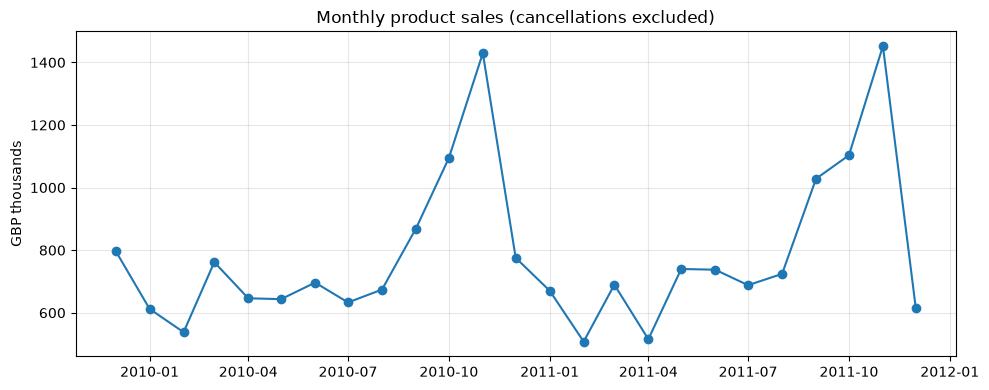

In [18]:
monthly = (
    df[~df.is_cancellation & df.is_product]
    .groupby("invoice_month").line_total.sum() / 1e3
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_title("Monthly product sales (cancellations excluded)")
ax.set_ylabel("GBP thousands")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_monthly_sales_sanity_check.png", dpi=150)
plt.show()

## 6. Save

In [19]:
out_path = PROCESSED_DIR / "transactions_clean.csv"
df.to_csv(out_path, index=False)
print(f"saved {len(df):,} rows -> {out_path}")

saved 1,027,016 rows -> D:\project-repo\data-analyst-portfolio\data\processed\transactions_clean.csv
